# 01. Exploratory Data Analysis (EDA) - King County House Sales
**Project**: End-to-End House Price Prediction  
**Dataset**: King County House Sales (21,613 records, 2014-2015 transactions)  

This notebook performs:
1. **Data Ingestion & Verification**: Loading raw sales data, verifying required schema, types, and null counts.
2. **Distribution Analysis**: Examining price skewness and verifying the log1p transformation.
3. **Correlation & Feature Relationships**: Pearson correlation heatmap and price vs. living area.
4. **Geographic Variations**: Pricing patterns across King County zipcodes.
5. **Data Quality & Outlier Analysis**: Identifying duplicate sales and diagnosing data entry anomalies (e.g., the 33-bedroom house).


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project root is in sys.path
sys.path.insert(0, os.path.abspath('..'))

from src.data import load_raw_data, clean_data
from src.eda import generate_eda_plots

# Style configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

## 1. Raw Dataset Ingestion and Schema Verification
Let's load `data/raw/kc_house_data.csv` and inspect its shape, column types, and summary statistics.

In [2]:
df_raw, diagnostics = load_raw_data("../data/raw/kc_house_data.csv")
print(f"Total Rows: {df_raw.shape[0]}, Total Columns: {df_raw.shape[1]}")
df_raw.head()

2026-10-28 10:41:02,069 [INFO] Loading raw dataset from ../data/raw/kc_house_data.csv...



DATASET DIAGNOSTICS
Shape: 21613 rows x 21 columns

Column Data Types & Non-Null Counts:
  - id             : int64      (Nulls: 0)
  - date           : object     (Nulls: 0)
  - price          : float64    (Nulls: 0)
  - bedrooms       : int64      (Nulls: 0)
  - bathrooms      : float64    (Nulls: 0)
  - sqft_living    : int64      (Nulls: 0)
  - sqft_lot       : int64      (Nulls: 0)
  - floors         : float64    (Nulls: 0)
  - waterfront     : int64      (Nulls: 0)
  - view           : int64      (Nulls: 0)
  - condition      : int64      (Nulls: 0)
  - grade          : int64      (Nulls: 0)
  - sqft_above     : int64      (Nulls: 0)
  - sqft_basement  : int64      (Nulls: 0)
  - yr_built       : int64      (Nulls: 0)
  - yr_renovated   : int64      (Nulls: 0)
  - zipcode        : int64      (Nulls: 0)
  - lat            : float64    (Nulls: 0)
  - long           : float64    (Nulls: 0)
  - sqft_living15  : int64      (Nulls: 0)
  - sqft_lot15     : int64      (Nulls: 0)

[OK] A

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


### Null Values and Data Types Check

In [3]:
null_counts = df_raw.isnull().sum()
print("Null values per column:")
print(null_counts[null_counts > 0] if null_counts.sum() > 0 else "Zero null values found across all columns.")

Null values per column:
Zero null values found across all columns.


## 2. Price Distribution and Log-Transform
Real estate sale prices are typically right-skewed due to luxury and estate properties.
Training linear and tree-based models directly on right-skewed targets can inflate errors on luxury properties. We apply `log1p(price)`.

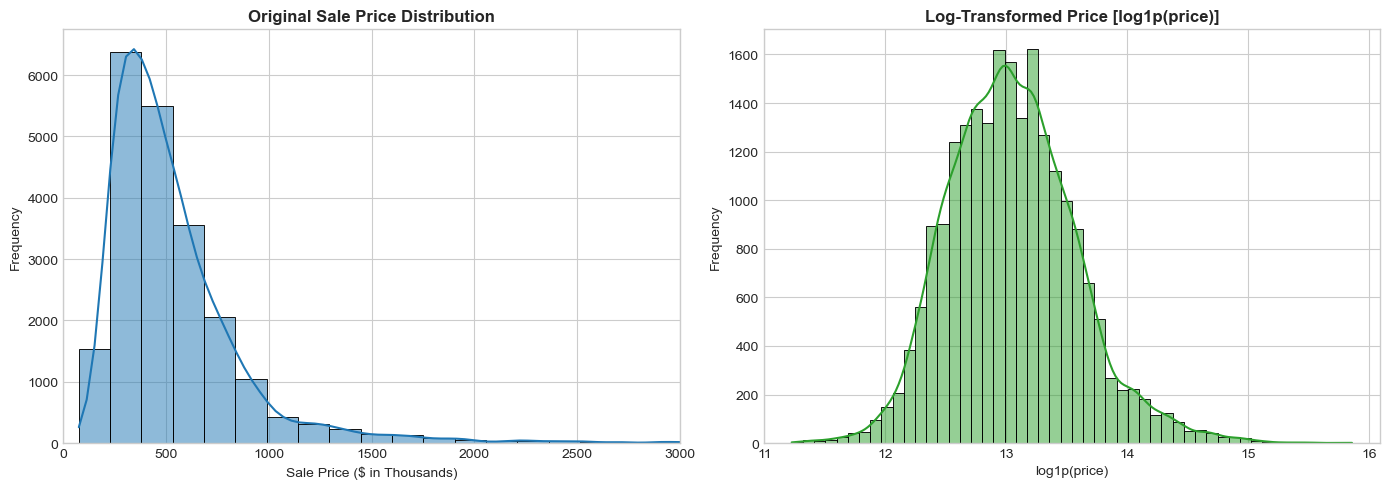

Original Price Skewness: 4.02
Log-Transformed Price Skewness: 0.43


In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Original Price
sns.histplot(df_raw['price'] / 1e3, kde=True, bins=50, color='#1f77b4', ax=ax1)
ax1.set_title("Original Sale Price Distribution", fontsize=12, fontweight='bold')
ax1.set_xlabel("Sale Price ($ in Thousands)")
ax1.set_ylabel("Frequency")
ax1.set_xlim(0, 3000)

# Log-Price
log_p = np.log1p(df_raw['price'])
sns.histplot(log_p, kde=True, bins=50, color='#2ca02c', ax=ax2)
ax2.set_title("Log-Transformed Price [log1p(price)]", fontsize=12, fontweight='bold')
ax2.set_xlabel("log1p(price)")
ax2.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

print(f"Original Price Skewness: {df_raw['price'].skew():.2f}")
print(f"Log-Transformed Price Skewness: {log_p.skew():.2f}")

## 3. Pearson Correlation Analysis
We calculate the Pearson correlation coefficients with property price to identify the strongest predictors.

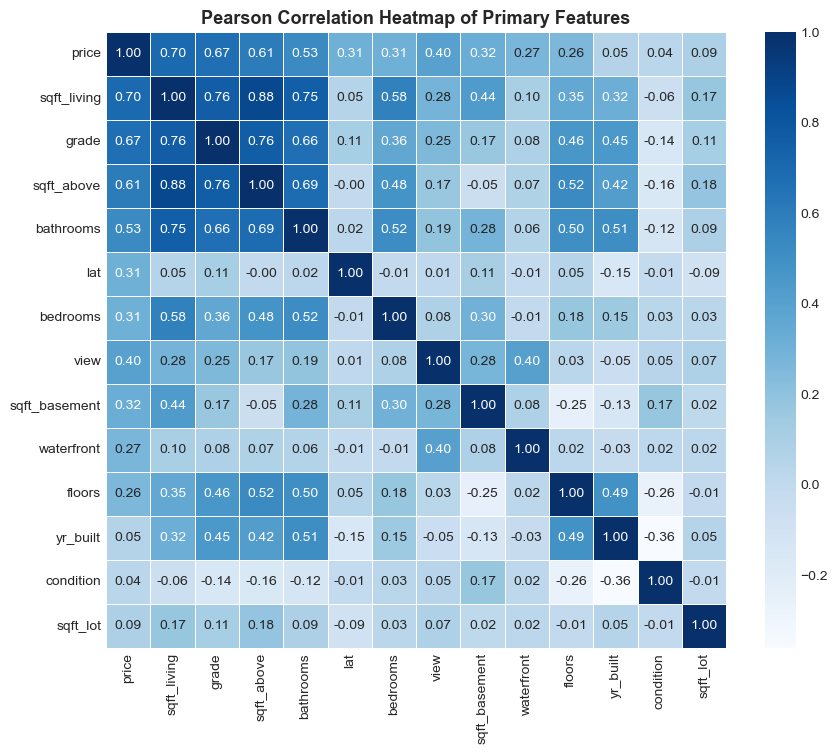

In [5]:
corr_cols = [
    'price', 'sqft_living', 'grade', 'sqft_above', 'bathrooms',
    'lat', 'bedrooms', 'view', 'sqft_basement', 'waterfront',
    'floors', 'yr_built', 'condition', 'sqft_lot'
]
corr_matrix = df_raw[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='Blues', linewidths=0.5)
plt.title("Pearson Correlation Heatmap of Primary Features", fontsize=13, fontweight='bold')
plt.show()

## 4. Price vs. Interior Living Space (sqft_living)
Living area (`sqft_living`) is the single strongest physical predictor (r = 0.70).
Coloring by King County construction grade illustrates how property quality compounds price per square foot.

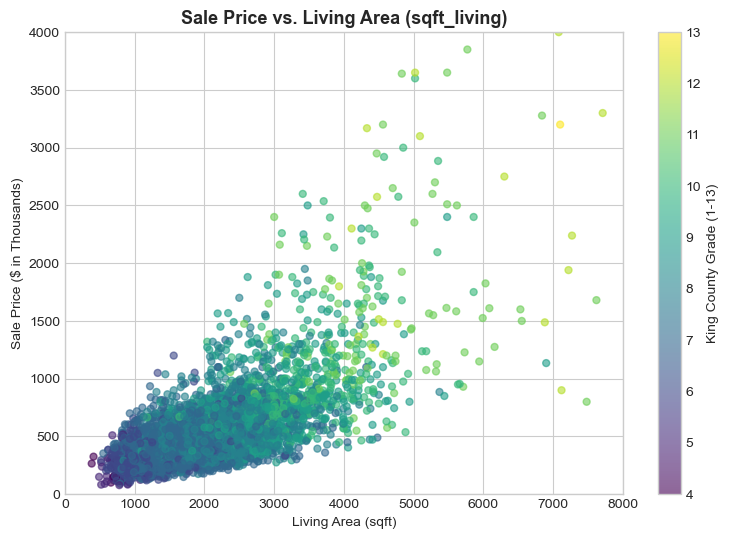

In [6]:
sample = df_raw.sample(n=min(5000, len(df_raw)), random_state=42)
plt.figure(figsize=(9, 6))
sc = plt.scatter(sample['sqft_living'], sample['price'] / 1e3, c=sample['grade'], cmap='viridis', alpha=0.6, s=25)
plt.colorbar(sc, label="King County Grade (1-13)")
plt.title("Sale Price vs. Living Area (sqft_living)", fontsize=13, fontweight='bold')
plt.xlabel("Living Area (sqft)")
plt.ylabel("Sale Price ($ in Thousands)")
plt.ylim(0, 4000)
plt.xlim(0, 8000)
plt.show()

## 5. Location Analysis: Price by Zipcode
Location is paramount in King County. Waterfront and Eastside zipcodes (Medina, Bellevue, Mercer Island) command premiums exceeding $1,000,000 median, while southern rural zipcodes have medians under $300,000.

2026-10-28 10:41:03,717 [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-10-28 10:41:03,718 [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


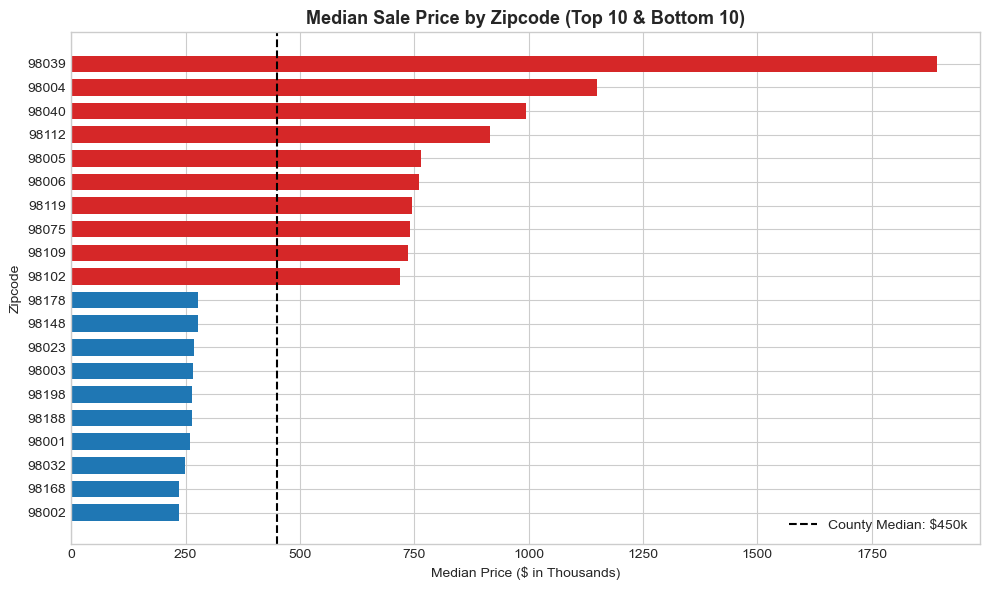

In [7]:
zip_medians = df_raw.groupby('zipcode')['price'].median().sort_values()
top_bottom_10 = pd.concat([zip_medians.head(10), zip_medians.tail(10)]) / 1e3

plt.figure(figsize=(10, 6))
colors = ['#1f77b4'] * 10 + ['#d62728'] * 10
plt.barh([str(z) for z in top_bottom_10.index], top_bottom_10.values, color=colors, height=0.7)
plt.axvline(df_raw['price'].median() / 1e3, color='black', linestyle='--', label=f'County Median: ${df_raw["price"].median()/1e3:.0f}k')
plt.title("Median Sale Price by Zipcode (Top 10 & Bottom 10)", fontsize=13, fontweight='bold')
plt.xlabel("Median Price ($ in Thousands)")
plt.ylabel("Zipcode")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Outlier Analysis & Data Cleaning
We inspect:
1. Duplicate property sales (re-sales within 2014-2015).
2. The infamous 33-bedroom property record (ID 2402100895).
3. Non-residential records (0 bedrooms or 0 bathrooms).

In [8]:
df_clean, summary = clean_data(df_raw, output_path="../data/processed/kc_house_data_clean.csv")
print("Cleaning Summary:")
for k, v in summary.items():
    print(f"  {k}: {v}")

2026-10-28 10:41:03,955 [INFO] Starting data cleaning on 21613 records...


2026-10-28 10:41:03,977 [INFO] Deduplication: dropped 177 earlier sales (retained latest transaction per property).


2026-10-28 10:41:03,979 [INFO] Identified 1 anomalous row with 33 bedrooms (id: [2402100895]).


2026-10-28 10:41:03,980 [INFO] Identified 16 records with 0 bedrooms or 0 bathrooms.


2026-10-28 10:41:03,982 [INFO] Domain outlier filter: removing 25 non-residential or extreme outlier records.


2026-10-28 10:41:03,986 [INFO] Cleaning complete: 21411 rows retained (99.07% of raw dataset).


2026-10-28 10:41:04,145 [INFO] Cleaned dataset saved to ../data/processed/kc_house_data_clean.csv


Cleaning Summary:
  initial_rows: 21613
  duplicate_sales_dropped: 177
  retained_unique_properties: 21436
  outlier_rows_dropped: 25
  final_cleaned_rows: 21411
  total_rows_removed: 202
  percentage_retained: 99.07


## Summary of EDA Takeaways
- **Target Skewness**: Right-skewed distribution (`skew = 4.02`) normalized via `log1p(price)` (`skew = 0.43`).
- **Key Predictors**: Construction grade, living area, bathrooms, latitude, and proximity to Seattle downtown.
- **Data Quality**: 177 earlier duplicate sales removed, retaining 21,436 unique properties. Erroneous 33-bedroom entry and non-residential properties removed (25 rows total, 99.07% retention).
